# Fashion-MNIST 多层全连接神经网络完整案例

这个 Notebook 使用 **Fashion-MNIST** 数据集识别 10 类服饰图片。  
和单层 Softmax / 单层 Dense 分类器不同，本案例使用的是 **多层全连接神经网络**，也叫：

```text
Multilayer Perceptron，简称 MLP
```

本案例明确 **不使用 CNN**：

- 不使用 `Conv2D`
- 不使用 `MaxPooling2D`
- 不使用卷积核提取局部图像特征

我们仍然把 28×28 图片拉平成 784 个像素特征，  
再交给多层 Dense 网络学习更复杂的像素组合规律。

---

# 第 0 步：环境准备

如果还没有安装相关库，可以在终端中运行：

```bash
python -m pip install tensorflow matplotlib numpy
```

如果在 Notebook 中安装，也可以新建一个代码单元格执行：

```python
!python -m pip install tensorflow matplotlib numpy
```

本案例主要使用：

- `tensorflow`：构建和训练神经网络
- `keras`：TensorFlow 中的高级神经网络接口
- `numpy`：处理数组和数值计算
- `matplotlib`：画图和展示图片
- `random`：固定随机性，便于复现实验

In [1]:
# ============================================================
# 第 0 步：环境准备与库导入
# ============================================================

import os

# ------------------------------------------------------------
# 重要：必须在导入 tensorflow / keras 之前设置。
#
# 原因：
# 本案例使用 TensorFlow，因此这里强制指定 Keras 后端为 tensorflow。
# ------------------------------------------------------------
os.environ["KERAS_BACKEND"] = "tensorflow"

# ------------------------------------------------------------
# 控制 TensorFlow 日志级别。
# 1 表示隐藏一部分不影响学习的提示信息。
# ------------------------------------------------------------
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "1"

import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow 版本：", tf.__version__)
print("Keras 版本：", keras.__version__)
print("当前 Keras 后端已设置为：tensorflow")

TensorFlow 版本： 2.21.0
Keras 版本： 3.14.1
当前 Keras 后端已设置为：tensorflow


# 第 0.1 步：设置中文字体

如果图表中的中文显示为方框，通常是因为 Matplotlib 没有找到中文字体。

下面的设置会尽量匹配常见中文字体：

- macOS：`PingFang SC`、`Heiti SC`、`Arial Unicode MS`
- Windows：`Microsoft YaHei`、`SimHei`
- Linux：`Noto Sans CJK SC`、`WenQuanYi Zen Hei`

如果你的电脑中没有这些字体，可以把自己系统里的中文字体名称加入列表。

In [2]:
# ============================================================
# 第 0.1 步：设置 Matplotlib 中文字体
# ============================================================

def set_chinese_font():
    """
    设置 Matplotlib 中文字体。

    说明：
    1. Matplotlib 会按顺序寻找字体。
    2. 找到第一个系统中存在的字体后，就会使用它。
    3. 如果所有字体都不存在，中文可能仍然显示为方框。
    """
    plt.rcParams["font.sans-serif"] = [
        "PingFang SC",
        "Heiti SC",
        "Arial Unicode MS",
        "Microsoft YaHei",
        "SimHei",
        "Noto Sans CJK SC",
        "WenQuanYi Zen Hei",
        "DejaVu Sans",
    ]

    # 解决坐标轴负号显示异常的问题。
    plt.rcParams["axes.unicode_minus"] = False

set_chinese_font()
print("中文字体设置完成。")

中文字体设置完成。


# 第 0.2 步：固定随机种子

神经网络训练中有很多随机因素，例如：

- 参数初始化
- 数据打乱
- Dropout 随机丢弃神经元
- 随机抽取图片展示

固定随机种子后，每次运行结果会尽量接近，方便课堂演示和对照观察。

In [3]:
# ============================================================
# 第 0.2 步：固定随机种子
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("随机种子已固定：", SEED)

随机种子已固定： 42


# 第 1 步：加载 Fashion-MNIST 数据集

Fashion-MNIST 是一个服饰图像分类数据集。

它包含：

- 60,000 张训练图片
- 10,000 张测试图片
- 每张图片大小为 28×28
- 每张图片是灰度图
- 每张图片属于 10 个类别之一

这 10 个类别分别是：

| 标签编号 | 英文类别 | 中文含义 |
|---|---|---|
| 0 | T-shirt/top | T恤 / 上衣 |
| 1 | Trouser | 裤子 |
| 2 | Pullover | 套头衫 |
| 3 | Dress | 连衣裙 |
| 4 | Coat | 外套 |
| 5 | Sandal | 凉鞋 |
| 6 | Shirt | 衬衫 |
| 7 | Sneaker | 运动鞋 |
| 8 | Bag | 包 |
| 9 | Ankle boot | 短靴 |

In [4]:
# ============================================================
# 第 1 步：加载 Fashion-MNIST 数据集
# ============================================================

# Fashion-MNIST 是 Keras 内置数据集之一。
# 返回值结构：
#
# (x_train_full, y_train_full), (x_test, y_test)
#
# x 表示图片数据。
# y 表示类别标签。
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

class_names_en = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot",
]

class_names_cn = [
    "T恤/上衣",
    "裤子",
    "套头衫",
    "连衣裙",
    "外套",
    "凉鞋",
    "衬衫",
    "运动鞋",
    "包",
    "短靴",
]

print("训练图片形状：", x_train_full.shape)
print("训练标签形状：", y_train_full.shape)
print("测试图片形状：", x_test.shape)
print("测试标签形状：", y_test.shape)
print("单张图片形状：", x_train_full[0].shape)
print("第一张图片标签编号：", y_train_full[0])
print("第一张图片中文类别：", class_names_cn[y_train_full[0]])

训练图片形状： (60000, 28, 28)
训练标签形状： (60000,)
测试图片形状： (10000, 28, 28)
测试标签形状： (10000,)
单张图片形状： (28, 28)
第一张图片标签编号： 9
第一张图片中文类别： 短靴


# 第 2 步：观察一批原始图片

在训练模型之前，先观察数据长什么样。

这一步可以帮助你理解：

- 图片是不是灰度图
- 类别之间是否容易区分
- 图片和标签是否对应
- 为什么 Fashion-MNIST 比手写数字 MNIST 更难

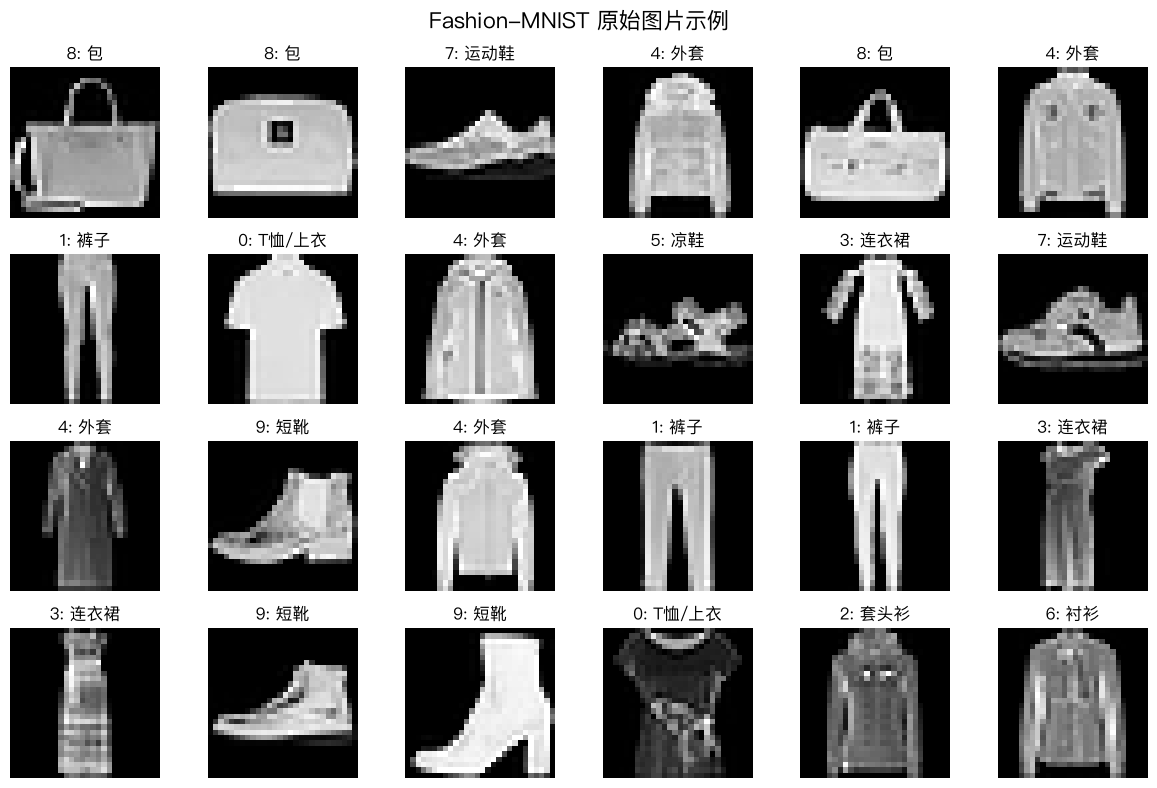

In [5]:
# ============================================================
# 第 2 步：展示一批 Fashion-MNIST 原始图片
# ============================================================

sample_indices = np.random.choice(len(x_train_full), size=24, replace=False)

plt.figure(figsize=(12, 8))

for plot_position, image_index in enumerate(sample_indices, start=1):
    image = x_train_full[image_index]
    label = y_train_full[image_index]

    plt.subplot(4, 6, plot_position)
    plt.imshow(image, cmap="gray")
    plt.title(f"{label}: {class_names_cn[label]}")
    plt.axis("off")

plt.suptitle("Fashion-MNIST 原始图片示例", fontsize=16)
plt.tight_layout()
plt.show()

# 第 3 步：观察标签分布

分类任务最好先看每个类别的数据数量。

如果某些类别特别多，某些类别特别少，模型可能偏向数量更多的类别。  
这种情况叫 **类别不平衡**。

Fashion-MNIST 通常比较均衡，每一类训练样本数量接近。

标签 0（T恤/上衣）：6000 张
标签 1（裤子）：6000 张
标签 2（套头衫）：6000 张
标签 3（连衣裙）：6000 张
标签 4（外套）：6000 张
标签 5（凉鞋）：6000 张
标签 6（衬衫）：6000 张
标签 7（运动鞋）：6000 张
标签 8（包）：6000 张
标签 9（短靴）：6000 张


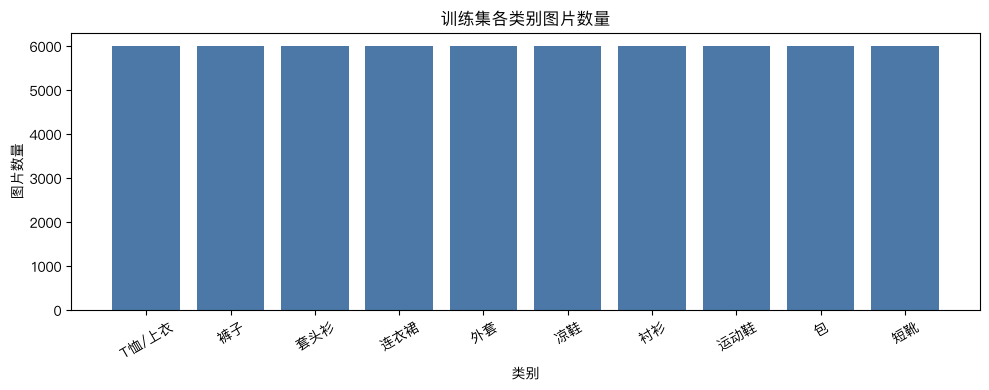

In [6]:
# ============================================================
# 第 3 步：观察训练集标签分布
# ============================================================

label_counts = np.bincount(y_train_full, minlength=10)

for label_id, count in enumerate(label_counts):
    print(f"标签 {label_id}（{class_names_cn[label_id]}）：{count} 张")

plt.figure(figsize=(10, 4))
plt.bar(class_names_cn, label_counts, color="#4C78A8")
plt.title("训练集各类别图片数量")
plt.xlabel("类别")
plt.ylabel("图片数量")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# 第 4 步：观察一张图片背后的像素矩阵

人看到的是一张服饰图片。  
计算机看到的是一个 28×28 的数字矩阵。

每个数字代表一个像素点的亮度：

```text
0   表示黑色
255 表示白色
中间值表示不同程度的灰色
```

神经网络并不是直接“看懂”衣服，  
而是从这些像素数字和标签之间学习规律。

示例图片编号： 0
标签编号： 9
中文类别： 短靴
图片形状： (28, 28)
像素最小值： 0
像素最大值： 255
像素数据类型： uint8


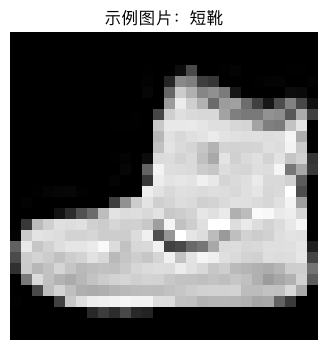

图片左上角 8×8 像素矩阵：
[[0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]]


In [7]:
# ============================================================
# 第 4 步：选择一张图片，观察它背后的像素矩阵
# ============================================================

example_index = 0
example_image = x_train_full[example_index]
example_label = y_train_full[example_index]

print("示例图片编号：", example_index)
print("标签编号：", example_label)
print("中文类别：", class_names_cn[example_label])
print("图片形状：", example_image.shape)
print("像素最小值：", example_image.min())
print("像素最大值：", example_image.max())
print("像素数据类型：", example_image.dtype)

plt.figure(figsize=(4, 4))
plt.imshow(example_image, cmap="gray")
plt.title(f"示例图片：{class_names_cn[example_label]}")
plt.axis("off")
plt.show()

print("图片左上角 8×8 像素矩阵：")
print(example_image[:8, :8])

# 第 5 步：放大显示像素值

28×28 一共有 784 个像素。  
直接打印完整矩阵不方便观察。

下面把图片放大，并在非零像素位置标出像素值，  
可以更直观看到服饰轮廓是由哪些数字组成的。

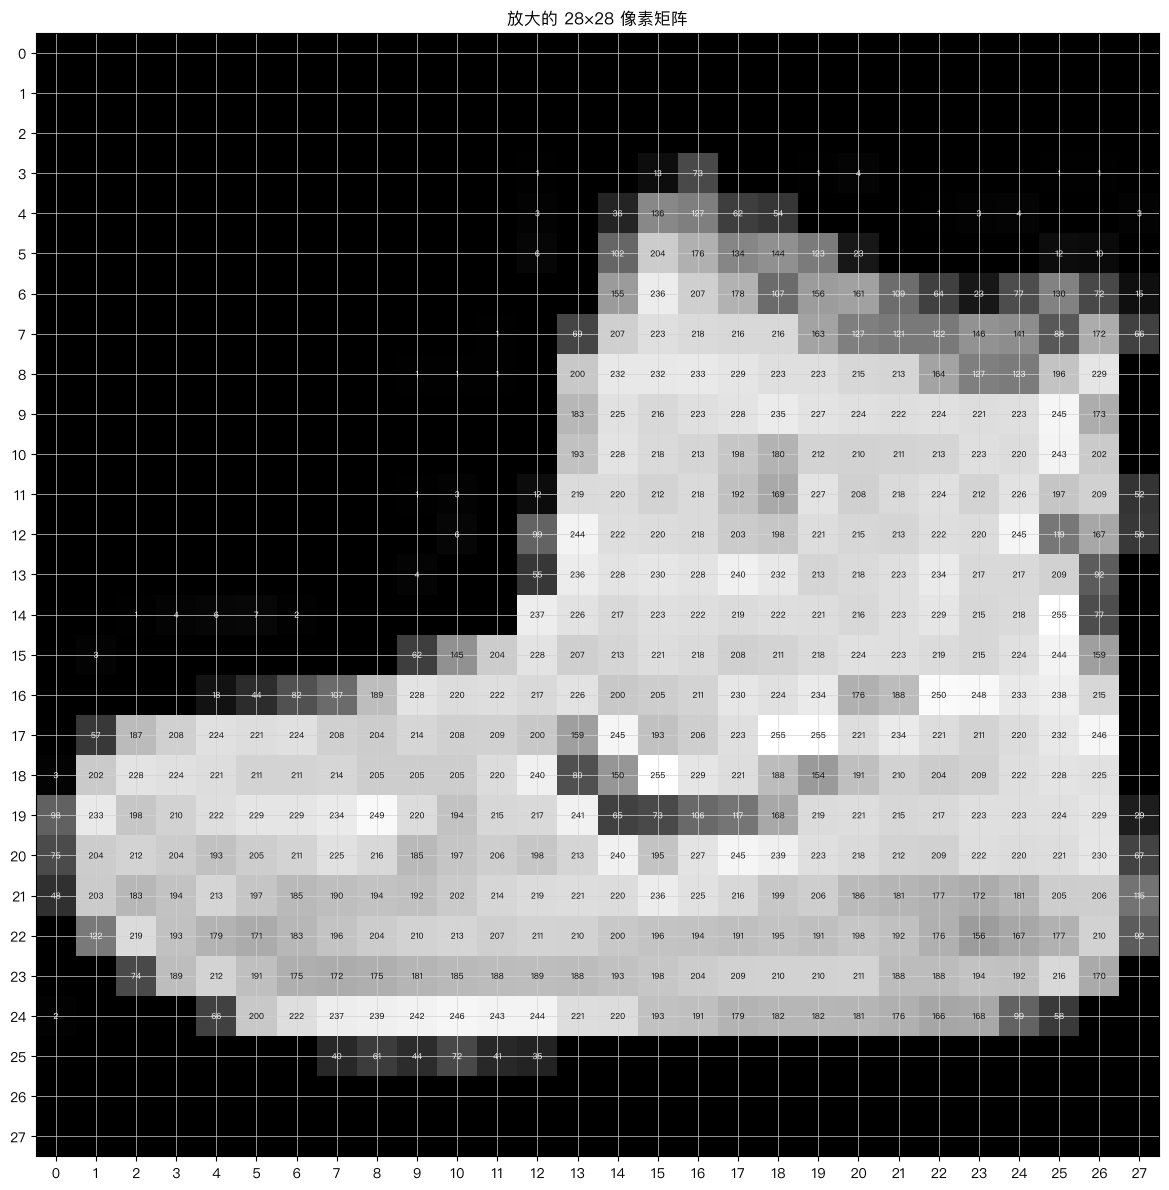

In [8]:
# ============================================================
# 第 5 步：放大图片，并标出非零像素值
# ============================================================

plt.figure(figsize=(12, 12))
plt.imshow(example_image, cmap="gray")

for row in range(example_image.shape[0]):
    for col in range(example_image.shape[1]):
        value = example_image[row, col]

        # 只标出非零像素，避免画面过于拥挤。
        if value > 0:
            text_color = "white" if value < 130 else "black"
            plt.text(col, row, str(value), ha="center", va="center", fontsize=6, color=text_color)

plt.title("放大的 28×28 像素矩阵")
plt.xticks(range(28))
plt.yticks(range(28))
plt.grid(color="lightgray", linewidth=0.5)
plt.tight_layout()
plt.show()

# 第 6 步：数据归一化

原始像素值范围是：

```text
0 到 255
```

神经网络训练通常更适合处理较小、稳定的数值范围。  
所以我们把像素值除以 255，变成：

```text
0 到 1
```

例如：

```text
0 / 255 = 0
128 / 255 ≈ 0.502
255 / 255 = 1
```

In [9]:
# ============================================================
# 第 6 步：数据归一化，把像素值从 0~255 转换到 0~1
# ============================================================

x_train_full_normalized = x_train_full.astype("float32") / 255.0
x_test_normalized = x_test.astype("float32") / 255.0

example_image_normalized = x_train_full_normalized[example_index]

print("归一化前像素最小值：", x_train_full.min())
print("归一化前像素最大值：", x_train_full.max())
print("归一化后像素最小值：", x_train_full_normalized.min())
print("归一化后像素最大值：", x_train_full_normalized.max())
print("归一化后数据类型：", x_train_full_normalized.dtype)

print("\n同一个像素归一化前后对比：")
row, col = 10, 10
print("原始值：", x_train_full[example_index, row, col])
print("归一化后：", x_train_full_normalized[example_index, row, col])

归一化前像素最小值： 0
归一化前像素最大值： 255
归一化后像素最小值： 0.0
归一化后像素最大值： 1.0
归一化后数据类型： float32

同一个像素归一化前后对比：
原始值： 0
归一化后： 0.0


# 第 7 步：拆分训练集和验证集

原始数据已经分成训练集和测试集。  
为了在训练过程中观察模型对新数据的表现，我们再从训练集中分出一部分作为验证集。

最终有三部分：

| 数据集 | 作用 |
|---|---|
| 训练集 | 用来调整模型参数 |
| 验证集 | 训练过程中观察模型表现 |
| 测试集 | 训练结束后做最终评估 |

测试集不要参与训练过程，否则最终评估会不够客观。

In [10]:
# ============================================================
# 第 7 步：拆分训练集和验证集
# ============================================================

indices = np.random.permutation(len(x_train_full_normalized))

validation_size = 10000
validation_indices = indices[:validation_size]
train_indices = indices[validation_size:]

x_val = x_train_full_normalized[validation_indices]
y_val = y_train_full[validation_indices]

x_train = x_train_full_normalized[train_indices]
y_train = y_train_full[train_indices]

print("训练集图片形状：", x_train.shape)
print("训练集标签形状：", y_train.shape)
print("验证集图片形状：", x_val.shape)
print("验证集标签形状：", y_val.shape)
print("测试集图片形状：", x_test_normalized.shape)
print("测试集标签形状：", y_test.shape)

训练集图片形状： (50000, 28, 28)
训练集标签形状： (50000,)
验证集图片形状： (10000, 28, 28)
验证集标签形状： (10000,)
测试集图片形状： (10000, 28, 28)
测试集标签形状： (10000,)


# 第 8 步：理解 Flatten

每张图片原本是：

```text
28 × 28
```

全连接神经网络接收的是一排输入特征。  
因此需要把二维矩阵拉平成一维向量：

```text
28 × 28 = 784
```

这个过程叫 **Flatten**。

Flatten 不会学习参数。  
它只改变数据形状：

```text
二维图片矩阵 → 一维像素向量
```

原始图片形状： (28, 28)
Flatten 后形状： (784,)
Flatten 后前 40 个像素值：
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


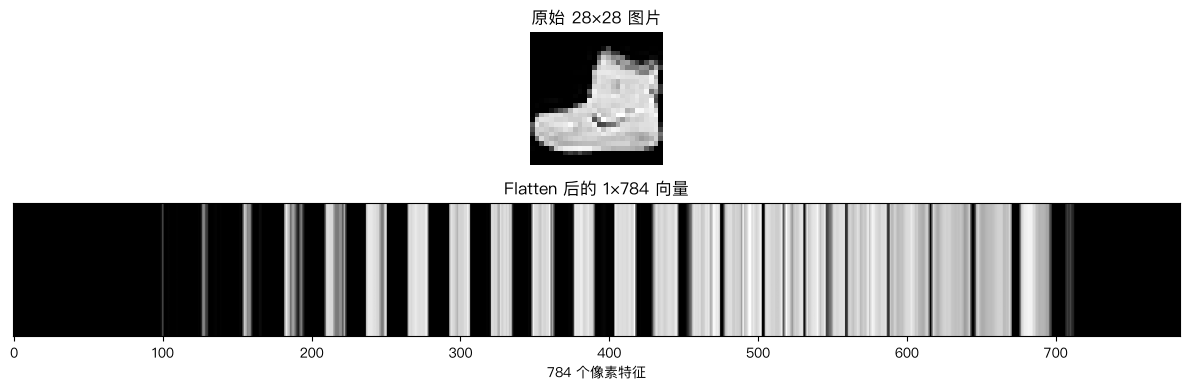

In [11]:
# ============================================================
# 第 8 步：Flatten，把 28×28 矩阵拉平成 784 个数字
# ============================================================

flatten_example = example_image_normalized.reshape(-1)

print("原始图片形状：", example_image_normalized.shape)
print("Flatten 后形状：", flatten_example.shape)
print("Flatten 后前 40 个像素值：")
print(flatten_example[:40])

plt.figure(figsize=(12, 4))

plt.subplot(2, 1, 1)
plt.imshow(example_image_normalized, cmap="gray")
plt.title("原始 28×28 图片")
plt.axis("off")

plt.subplot(2, 1, 2)
plt.imshow(flatten_example.reshape(1, 784), cmap="gray", aspect="auto")
plt.title("Flatten 后的 1×784 向量")
plt.yticks([])
plt.xlabel("784 个像素特征")

plt.tight_layout()
plt.show()

# 第 9 步：单层网络和多层网络的区别

单层 Softmax 分类器通常可以写成：

```text
输入 28×28 图片
        ↓
Flatten：784 个像素
        ↓
Dense：10 个神经元 + Softmax
```

这种模型本质上直接从 784 个像素映射到 10 个类别。  
它可以学习简单边界，但表达能力有限。

多层全连接神经网络会增加隐藏层：

```text
输入 28×28 图片
        ↓
Flatten：784 个像素
        ↓
Dense 隐藏层 1
        ↓
Dense 隐藏层 2
        ↓
Dense 隐藏层 3
        ↓
Dense：10 个神经元 + Softmax
```

隐藏层可以逐步组合像素特征。  
例如先学习边缘、暗亮区域、整体轮廓的组合，再学习不同服饰类别的差异。

注意：这里仍然不是 CNN。  
因为 Dense 层没有卷积核，也不会专门利用图片的局部空间结构。

In [12]:
# ============================================================
# 第 9 步：只构建一个单层 Softmax 模型用于结构对比
# ============================================================

single_layer_model = keras.Sequential([
    layers.Input(shape=(28, 28), name="single_input_28x28_image"),
    layers.Flatten(name="single_flatten_28x28_to_784"),
    layers.Dense(10, activation="softmax", name="single_output_10_softmax"),
])

single_layer_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

print("单层 Softmax 模型结构：")
single_layer_model.summary()
print("单层模型参数数量：", single_layer_model.count_params())

# 这个模型只是用来对比结构，不作为本案例的最终模型训练。

单层 Softmax 模型结构：


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ single_flatten_28x28_to_784     │ (None, 784)            │             0 │
│ (Flatten)                       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ single_output_10_softmax        │ (None, 10)             │         7,850 │
│ (Dense)                         │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,850 (30.66 KB)

 Trainable params: 7,850 (30.66 KB)

 Non-trainable params: 0 (0.00 B)

单层模型参数数量： 7850


# 第 10 步：构建多层全连接神经网络

本案例的主模型结构如下：

```text
输入：28×28 图像
        ↓
Flatten：拉平成 784 个数字
        ↓
Dense：256 个神经元，ReLU 激活
        ↓
Dropout：随机丢弃 30%
        ↓
Dense：128 个神经元，ReLU 激活
        ↓
Dropout：随机丢弃 20%
        ↓
Dense：64 个神经元，ReLU 激活
        ↓
Dense：10 个神经元，Softmax 输出概率
```

这里的 3 个 Dense 隐藏层就是“多层”的核心。  
它比单层 Softmax 有更强的表达能力，但仍然保持课堂上容易理解的结构。

---

## ReLU 是什么？

ReLU 的直观规则：

```text
如果输入小于 0，就输出 0
如果输入大于 0，就原样输出
```

ReLU 可以让网络学习非线性关系。  
没有非线性激活函数，多层线性变换叠在一起仍然接近一层线性变换。

---

## Dropout 是什么？

Dropout 会在训练时随机让一部分神经元暂时失效。  
这样可以减少模型对训练集的死记硬背，降低过拟合风险。

In [13]:
# ============================================================
# 第 10 步：构建多层全连接神经网络模型
# ============================================================

# ------------------------------------------------------------
# 重要提醒：
# Keras 层的 name 使用英文安全命名。
# 中文解释写在注释、Markdown、print 或图表标题中。
# ------------------------------------------------------------

model = keras.Sequential([
    # 输入层：
    # 每个样本是一张 28×28 的灰度图片。
    layers.Input(shape=(28, 28), name="input_28x28_image"),

    # Flatten 层：
    # 把二维图像拉平成 784 个输入特征。
    layers.Flatten(name="flatten_28x28_to_784"),

    # 第一个全连接隐藏层：
    # 256 个神经元，学习较丰富的像素组合特征。
    layers.Dense(256, activation="relu", name="hidden_dense_256_relu"),

    # Dropout：
    # 训练时随机让 30% 的神经元暂时失效，减少过拟合。
    layers.Dropout(0.30, name="dropout_30_percent"),

    # 第二个全连接隐藏层：
    # 128 个神经元，继续组合上一层学到的特征。
    layers.Dense(128, activation="relu", name="hidden_dense_128_relu"),

    # 再加一层 Dropout。
    layers.Dropout(0.20, name="dropout_20_percent"),

    # 第三个全连接隐藏层：
    # 64 个神经元，让特征进一步压缩，形成更抽象的表示。
    layers.Dense(64, activation="relu", name="hidden_dense_64_relu"),

    # 输出层：
    # 10 个神经元对应 10 个服饰类别。
    # Softmax 会把输出转换成 10 个概率。
    layers.Dense(10, activation="softmax", name="output_10_softmax"),
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

print("多层全连接神经网络结构：")
model.summary()
print("多层模型参数数量：", model.count_params())

多层全连接神经网络结构：


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_28x28_to_784 (Flatten)  │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_dense_256_relu (Dense)   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_30_percent (Dropout)    │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_dense_128_relu (Dense)   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_20_percent (Dropout)    │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_dense_64_relu (Dense)    │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_10_softmax (Dense)       │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 242,762 (948.29 KB)

 Trainable params: 242,762 (948.29 KB)

 Non-trainable params: 0 (0.00 B)

多层模型参数数量： 242762


# 第 10.1 步：理解参数数量

Dense 层的参数数量由两部分组成：

```text
权重数量 = 输入特征数 × 神经元数量
偏置数量 = 神经元数量
总参数数量 = 权重数量 + 偏置数量
```

第一层 Dense 接收 784 个输入特征，输出 256 个神经元：

```text
权重数量 = 784 × 256
偏置数量 = 256
总参数数量 = 784 × 256 + 256
```

后面的 Dense 层输入不再是 784，  
而是上一层输出的神经元数量。

In [14]:
# ============================================================
# 第 10.1 步：手动计算每个 Dense 层的参数数量
# ============================================================

layer_shapes = [
    (784, 256, "第一层 Dense：784 → 256"),
    (256, 128, "第二层 Dense：256 → 128"),
    (128, 64, "第三层 Dense：128 → 64"),
    (64, 10, "输出层 Dense：64 → 10"),
]

manual_total_params = 0

for input_count, neuron_count, layer_name in layer_shapes:
    weight_count = input_count * neuron_count
    bias_count = neuron_count
    total_count = weight_count + bias_count
    manual_total_params += total_count

    print(layer_name)
    print("  权重数量：", weight_count)
    print("  偏置数量：", bias_count)
    print("  本层参数数量：", total_count)

print("\n手动计算的 Dense 总参数数量：", manual_total_params)
print("Keras 模型统计的总参数数量：", model.count_params())

第一层 Dense：784 → 256
  权重数量： 200704
  偏置数量： 256
  本层参数数量： 200960
第二层 Dense：256 → 128
  权重数量： 32768
  偏置数量： 128
  本层参数数量： 32896
第三层 Dense：128 → 64
  权重数量： 8192
  偏置数量： 64
  本层参数数量： 8256
输出层 Dense：64 → 10
  权重数量： 640
  偏置数量： 10
  本层参数数量： 650

手动计算的 Dense 总参数数量： 242762
Keras 模型统计的总参数数量： 242762


# 第 11 步：训练模型

训练时，每一轮 `epoch` 大致发生：

1. 模型读取一批图片。
2. 根据当前参数输出预测概率。
3. 将预测结果和真实标签比较。
4. 计算损失值。
5. 通过反向传播计算参数应该如何调整。
6. 优化器更新参数。
7. 重复以上过程。

---

## batch_size

```python
batch_size=128
```

表示每次使用 128 张图片计算一次参数更新。

---

## epochs

```python
epochs=12
```

表示完整看完训练集 12 次。  
如果课堂演示想更快，可以改成 5。  
如果想观察更充分的训练过程，可以改成 15 或 20。

In [15]:
# ============================================================
# 第 11 步：开始训练多层全连接神经网络
# ============================================================

EPOCHS = 12
BATCH_SIZE = 128

history = model.fit(
    x_train,
    y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(x_val, y_val),
)

Epoch 1/12
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7700 - loss: 0.6480 - val_accuracy: 0.8293 - val_loss: 0.4469
Epoch 2/12
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8395 - loss: 0.4424 - val_accuracy: 0.8585 - val_loss: 0.3873
Epoch 3/12
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8534 - loss: 0.4027 - val_accuracy: 0.8618 - val_loss: 0.3737
Epoch 4/12
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8630 - loss: 0.3762 - val_accuracy: 0.8670 - val_loss: 0.3566
Epoch 5/12
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8696 - loss: 0.3568 - val_accuracy: 0.8685 - val_loss: 0.3557
Epoch 6/12
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8709 - loss: 0.3472 - val_accuracy: 0.8708 - val_loss: 0.3458
Epoch 7/12
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8764 - loss: 0.3343 - val_accuracy: 0.8731 - val_loss: 0.3354
Epoch 8/12
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8798 - loss: 0.3261 - val_accuracy: 0.

# 第 12 步：绘制训练过程曲线

训练结束后，重点观察两个指标：

1. `loss`：损失值，越低通常越好。
2. `accuracy`：准确率，越高通常越好。

同时观察训练集和验证集：

- 训练集表现好，说明模型能拟合已见过的数据。
- 验证集表现好，说明模型对新数据也有较好效果。
- 如果训练集越来越好，但验证集变差，可能出现过拟合。

history 中包含的指标： dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])


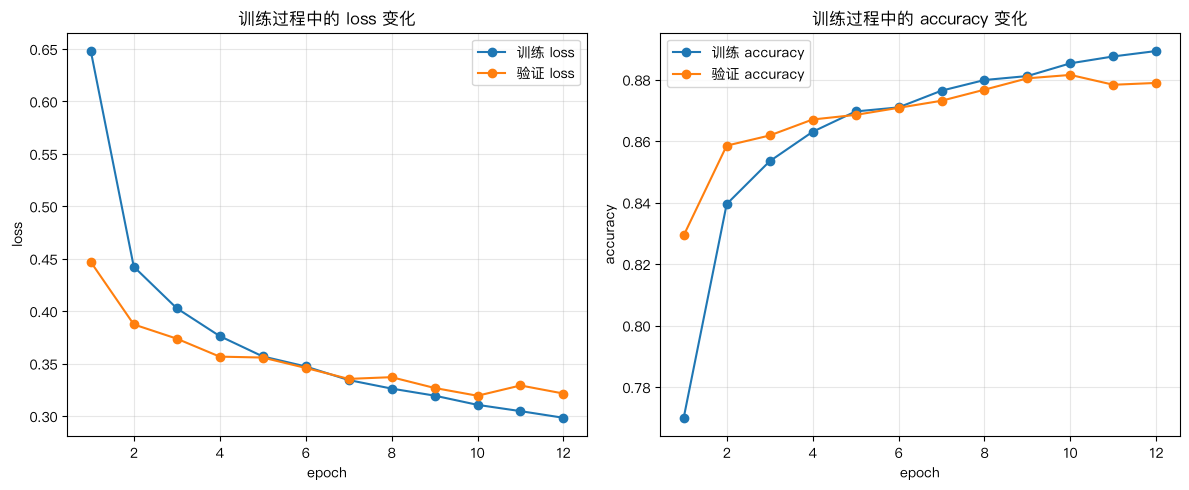

In [16]:
# ============================================================
# 第 12 步：绘制 loss 和 accuracy 变化曲线
# ============================================================

history_dict = history.history
print("history 中包含的指标：", history_dict.keys())

epoch_numbers = range(1, len(history_dict["loss"]) + 1)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epoch_numbers, history_dict["loss"], marker="o", label="训练 loss")
plt.plot(epoch_numbers, history_dict["val_loss"], marker="o", label="验证 loss")
plt.title("训练过程中的 loss 变化")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(epoch_numbers, history_dict["accuracy"], marker="o", label="训练 accuracy")
plt.plot(epoch_numbers, history_dict["val_accuracy"], marker="o", label="验证 accuracy")
plt.title("训练过程中的 accuracy 变化")
plt.xlabel("epoch")
plt.ylabel("accuracy")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# 第 13 步：在测试集上评估模型

测试集没有参与训练。  
所以测试集结果更能反映模型面对新图片时的表现。

这里会输出：

- 测试集 loss
- 测试集 accuracy

In [17]:
# ============================================================
# 第 13 步：使用测试集评估模型
# ============================================================

test_loss, test_accuracy = model.evaluate(x_test_normalized, y_test, verbose=0)

print("测试集 loss：", test_loss)
print("测试集 accuracy：", test_accuracy)
print(f"测试集准确率约为：{test_accuracy * 100:.2f}%")

测试集 loss： 0.35076019167900085
测试集 accuracy： 0.8756999969482422
测试集准确率约为：87.57%


# 第 14 步：观察单张图片的预测过程

模型最后输出 10 个概率。  
每个概率对应一个类别。

例如：

```text
T恤/上衣：0.03
裤子：0.01
套头衫：0.02
...
短靴：0.91
```

概率最大的类别，就是模型最终预测的类别。

真实标签编号： 9
真实类别： 短靴
预测标签编号： 9
预测类别： 短靴
预测是否正确： True


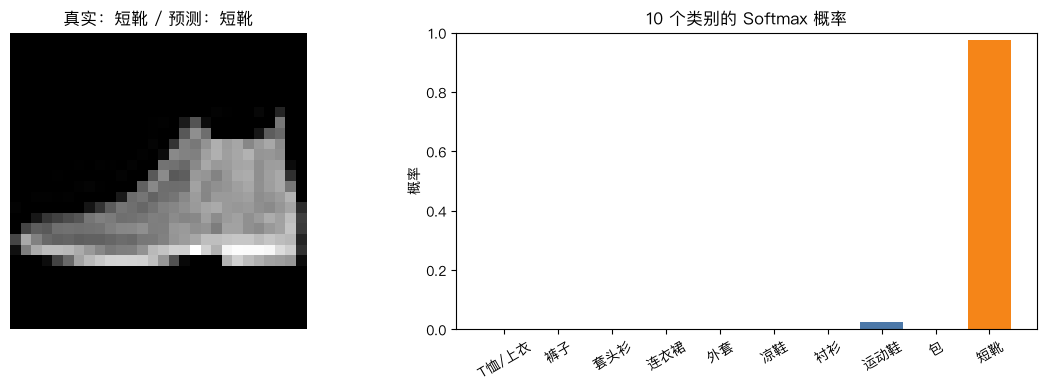

0 T恤/上衣：0.0000
1 裤子：0.0000
2 套头衫：0.0000
3 连衣裙：0.0000
4 外套：0.0000
5 凉鞋：0.0007
6 衬衫：0.0000
7 运动鞋：0.0253
8 包：0.0000
9 短靴：0.9740


In [18]:
# ============================================================
# 第 14 步：观察模型对单张图片的预测过程
# ============================================================

test_index = 0
single_image = x_test_normalized[test_index]
single_label = y_test[test_index]

# model.predict 需要一批图片。
# single_image 原本是一张图片，形状是 (28, 28)。
# np.expand_dims 会在最前面增加一个维度，变成 (1, 28, 28)。
single_image_batch = np.expand_dims(single_image, axis=0)

probabilities = model.predict(single_image_batch, verbose=0)[0]
predicted_label = np.argmax(probabilities)

print("真实标签编号：", single_label)
print("真实类别：", class_names_cn[single_label])
print("预测标签编号：", predicted_label)
print("预测类别：", class_names_cn[predicted_label])
print("预测是否正确：", predicted_label == single_label)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.imshow(single_image, cmap="gray")
plt.title(f"真实：{class_names_cn[single_label]} / 预测：{class_names_cn[predicted_label]}")
plt.axis("off")

plt.subplot(1, 2, 2)
bar_colors = ["#F58518" if i == predicted_label else "#4C78A8" for i in range(10)]
plt.bar(class_names_cn, probabilities, color=bar_colors)
plt.title("10 个类别的 Softmax 概率")
plt.ylabel("概率")
plt.ylim(0, 1)
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

for label_id, probability in enumerate(probabilities):
    print(f"{label_id} {class_names_cn[label_id]}：{probability:.4f}")

# 第 15 步：批量展示预测结果

下面展示测试集中前 30 张图片的预测结果。

标题含义：

```text
真：真实类别
预：预测类别
```

颜色含义：

- 绿色：预测正确
- 红色：预测错误

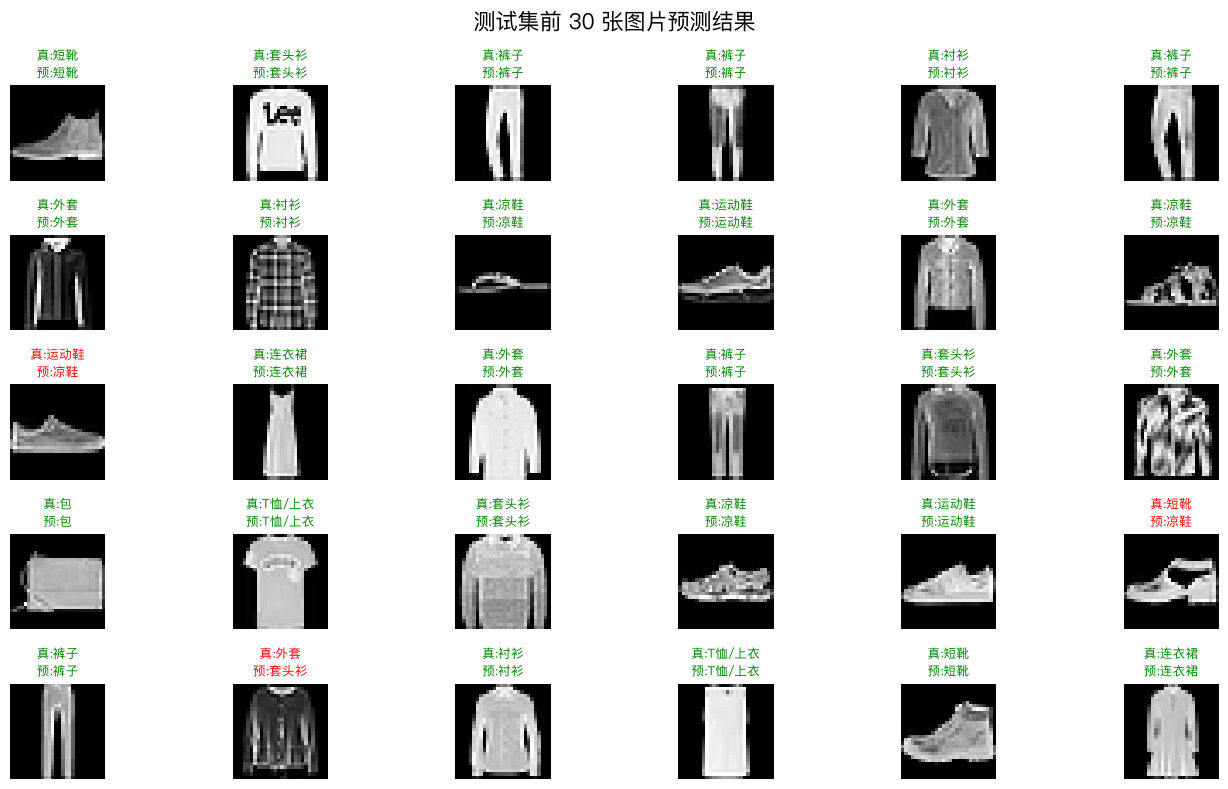

In [19]:
# ============================================================
# 第 15 步：批量展示测试集预测结果
# ============================================================

num_show = 30
predictions = model.predict(x_test_normalized[:num_show], verbose=0)
predicted_labels = np.argmax(predictions, axis=1)

plt.figure(figsize=(14, 8))

for i in range(num_show):
    true_label = y_test[i]
    predicted_label = predicted_labels[i]
    correct = true_label == predicted_label

    title_color = "green" if correct else "red"

    plt.subplot(5, 6, i + 1)
    plt.imshow(x_test_normalized[i], cmap="gray")
    plt.title(
        f"真:{class_names_cn[true_label]}\n预:{class_names_cn[predicted_label]}",
        color=title_color,
        fontsize=9,
    )
    plt.axis("off")

plt.suptitle("测试集前 30 张图片预测结果", fontsize=16)
plt.tight_layout()
plt.show()

# 第 16 步：混淆矩阵

混淆矩阵可以分析模型容易混淆哪些类别。

矩阵含义：

```text
行：真实类别
列：预测类别
```

例如：

```text
真实类别是 T恤/上衣，经常被预测成 衬衫
```

说明这两个类别在像素形状上比较相似，模型更容易混淆。

混淆矩阵：
[[820   1  11  36   1   0 126   0   5   0]
 [  2 965   1  21   5   0   6   0   0   0]
 [ 11   0 824  20  76   0  69   0   0   0]
 [ 18   6   5 911  20   0  35   0   5   0]
 [  0   1 159  57 724   0  58   0   1   0]
 [  0   0   0   0   0 953   0  30   0  17]
 [108   1  90  42  72   0 679   0   8   0]
 [  0   0   0   0   0  10   0 972   0  18]
 [  2   1   7   6   2   3  10  10 959   0]
 [  0   0   0   0   0   7   1  42   0 950]]


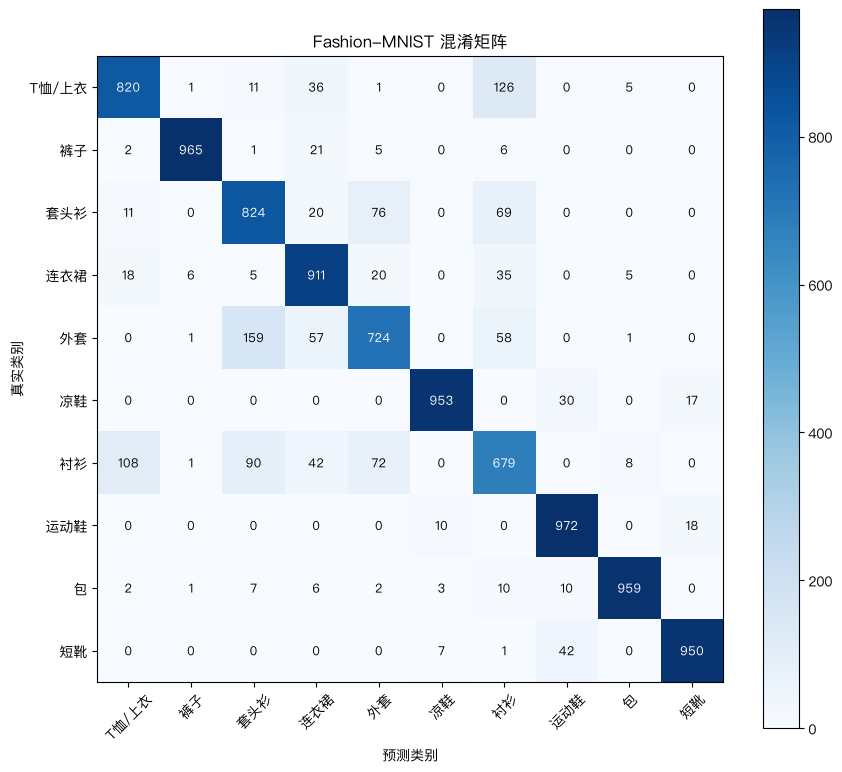

In [20]:
# ============================================================
# 第 16 步：计算并展示混淆矩阵
# ============================================================

all_predictions = model.predict(x_test_normalized, verbose=0)
all_predicted_labels = np.argmax(all_predictions, axis=1)

confusion_matrix = tf.math.confusion_matrix(
    labels=y_test,
    predictions=all_predicted_labels,
    num_classes=10,
).numpy()

print("混淆矩阵：")
print(confusion_matrix)

plt.figure(figsize=(9, 8))
plt.imshow(confusion_matrix, cmap="Blues")
plt.title("Fashion-MNIST 混淆矩阵")
plt.xlabel("预测类别")
plt.ylabel("真实类别")
plt.xticks(range(10), class_names_cn, rotation=45)
plt.yticks(range(10), class_names_cn)
plt.colorbar()

for row in range(10):
    for col in range(10):
        value = confusion_matrix[row, col]
        text_color = "white" if value > confusion_matrix.max() * 0.5 else "black"
        plt.text(col, row, str(value), ha="center", va="center", color=text_color, fontsize=9)

plt.tight_layout()
plt.show()

# 第 17 步：找出最容易混淆的类别

混淆矩阵中：

- 对角线表示预测正确的数量
- 非对角线表示预测错误的数量

下面找出非对角线中数量最多的几个错误组合。  
这可以帮助你理解模型主要错在哪里。

In [21]:
# ============================================================
# 第 17 步：分析最常见的错误组合
# ============================================================

cm_without_diagonal = confusion_matrix.copy()
np.fill_diagonal(cm_without_diagonal, 0)

flat_indices = np.argsort(cm_without_diagonal.ravel())[::-1]

top_k = 8
print(f"最常见的 {top_k} 类错误：")

shown = 0
for flat_index in flat_indices:
    true_label, predicted_label = np.unravel_index(flat_index, cm_without_diagonal.shape)
    count = cm_without_diagonal[true_label, predicted_label]

    if count == 0:
        break

    print(
        f"真实是 {class_names_cn[true_label]}，"
        f"被预测成 {class_names_cn[predicted_label]}：{count} 张"
    )

    shown += 1
    if shown >= top_k:
        break

最常见的 8 类错误：
真实是 外套，被预测成 套头衫：159 张
真实是 T恤/上衣，被预测成 衬衫：126 张
真实是 衬衫，被预测成 T恤/上衣：108 张
真实是 衬衫，被预测成 套头衫：90 张
真实是 套头衫，被预测成 外套：76 张
真实是 衬衫，被预测成 外套：72 张
真实是 套头衫，被预测成 衬衫：69 张
真实是 外套，被预测成 衬衫：58 张


# 第 18 步：展示预测错误的图片

只看数字指标还不够。  
直接观察错误图片，可以帮助你理解模型为什么会犯错。

常见原因包括：

1. 图片本身轮廓模糊。
2. 类别之间外形相似。
3. 服饰姿态、宽窄、边缘形状差异较大。
4. 全连接网络没有专门利用图像的局部空间结构。

第 4 点也是 CNN 在图像任务中常常更强的原因。  
但本案例目标是理解多层神经网络，所以暂时不使用 CNN。

测试集中一共有 1243 张预测错误。
测试集总数：10000
错误率约为：12.43%


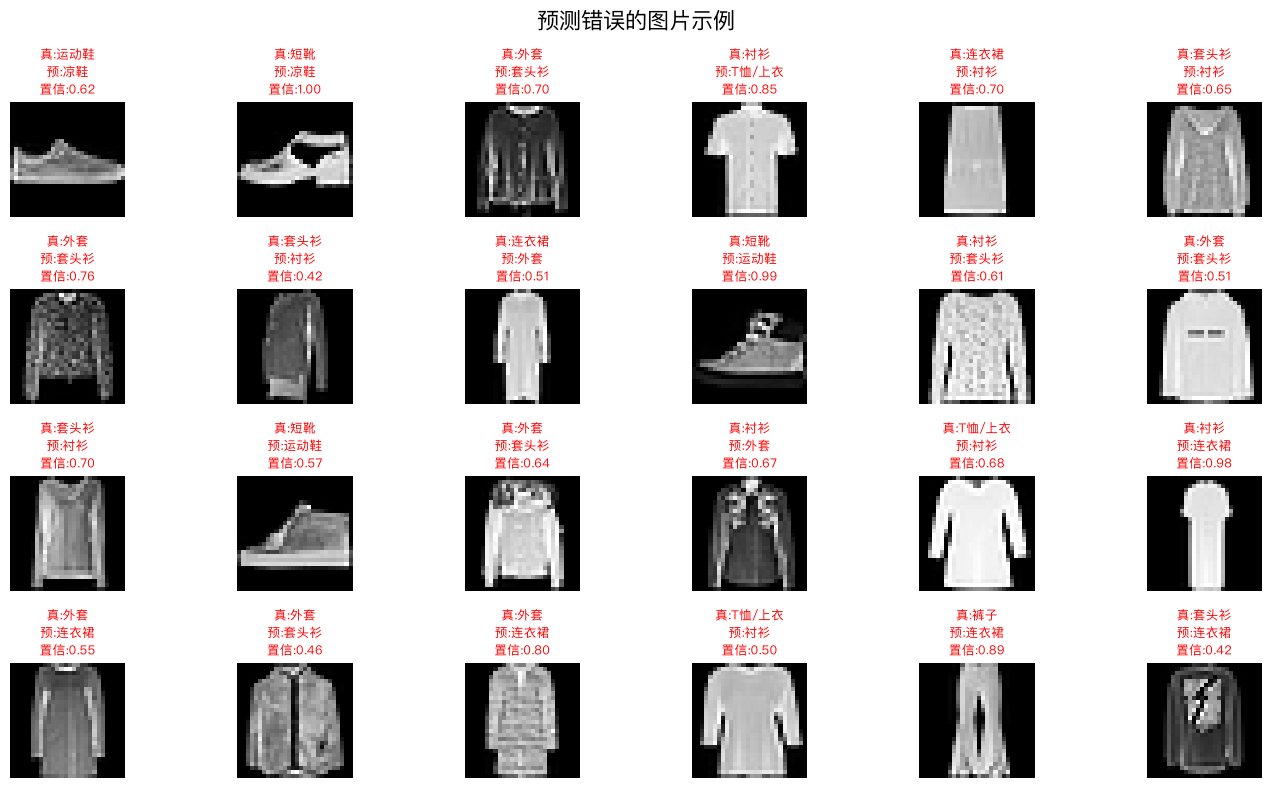

In [22]:
# ============================================================
# 第 18 步：展示模型预测错误的图片
# ============================================================

wrong_indices = np.where(all_predicted_labels != y_test)[0]

print(f"测试集中一共有 {len(wrong_indices)} 张预测错误。")
print(f"测试集总数：{len(y_test)}")
print(f"错误率约为：{len(wrong_indices) / len(y_test) * 100:.2f}%")

num_wrong_show = min(24, len(wrong_indices))
wrong_show_indices = wrong_indices[:num_wrong_show]

plt.figure(figsize=(14, 8))

for plot_position, image_index in enumerate(wrong_show_indices, start=1):
    true_label = y_test[image_index]
    predicted_label = all_predicted_labels[image_index]
    confidence = all_predictions[image_index, predicted_label]

    plt.subplot(4, 6, plot_position)
    plt.imshow(x_test_normalized[image_index], cmap="gray")
    plt.title(
        f"真:{class_names_cn[true_label]}\n预:{class_names_cn[predicted_label]}\n置信:{confidence:.2f}",
        color="red",
        fontsize=9,
    )
    plt.axis("off")

plt.suptitle("预测错误的图片示例", fontsize=16)
plt.tight_layout()
plt.show()

# 第 19 步：观察多张图片的 Softmax 概率分布

对于一张图片，模型不只是给出一个类别。  
它实际上输出 10 个类别的概率。

如果最高概率明显高于其他类别，说明模型比较“确定”。  
如果多个类别概率接近，说明模型比较“犹豫”。

下面展示几张图片及其 Softmax 概率分布。

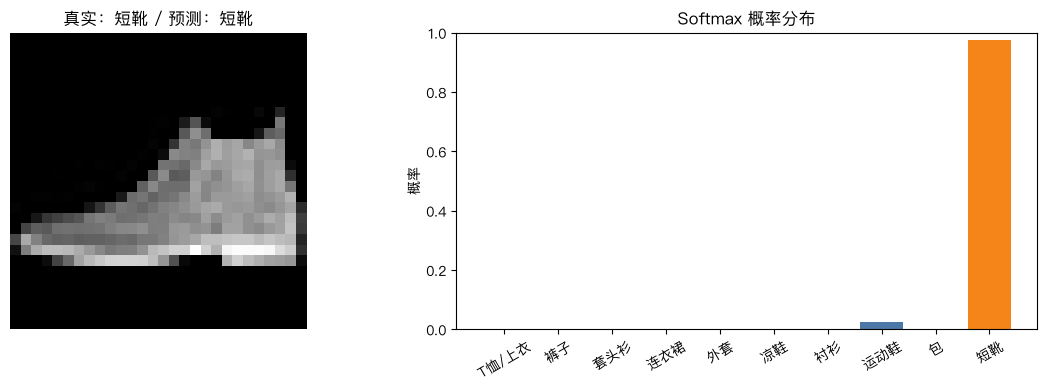

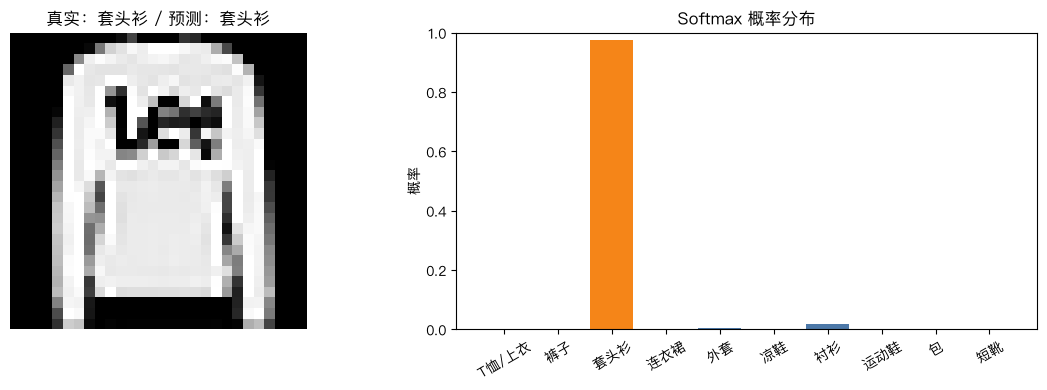

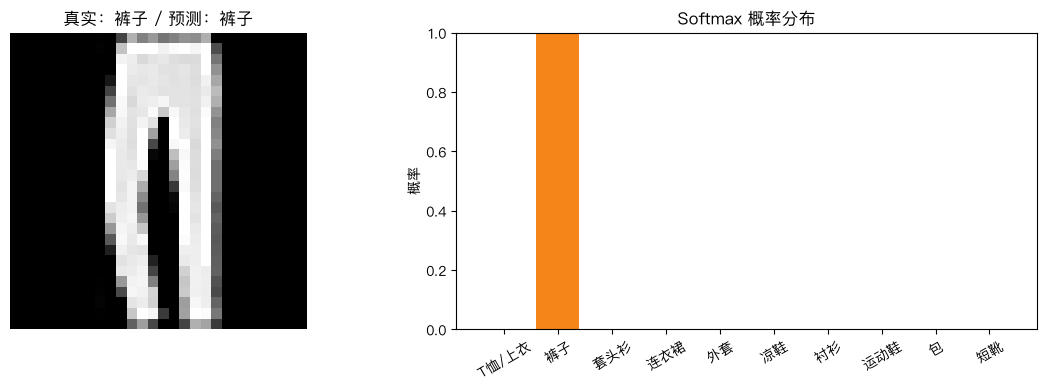

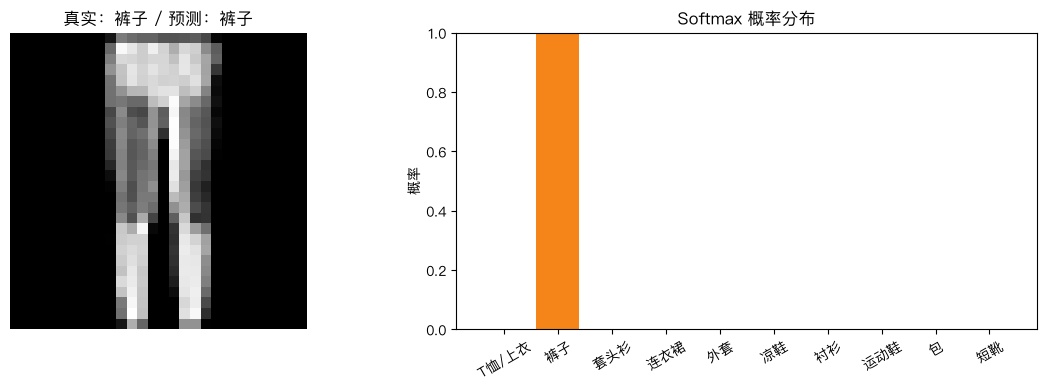

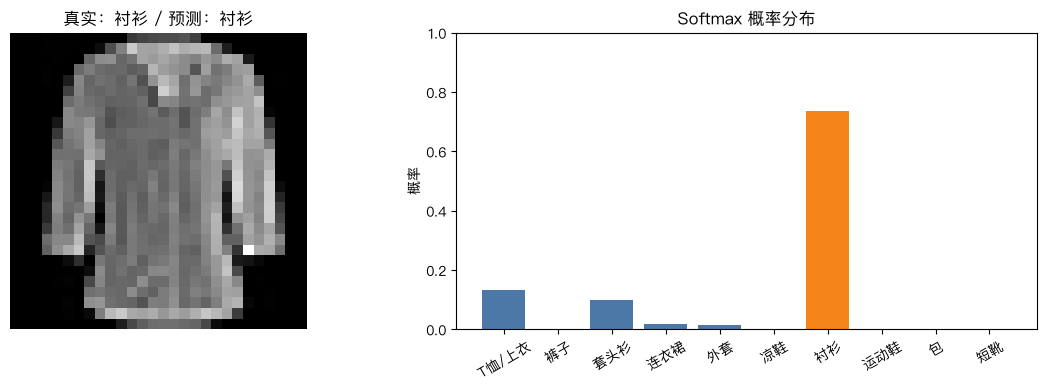

In [23]:
# ============================================================
# 第 19 步：展示多张图片的 Softmax 概率分布
# ============================================================

indices_to_show = [0, 1, 2, 3, 4]

for idx in indices_to_show:
    image = x_test_normalized[idx]
    true_label = y_test[idx]
    probability_vector = all_predictions[idx]
    predicted_label = np.argmax(probability_vector)

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(image, cmap="gray")
    plt.title(f"真实：{class_names_cn[true_label]} / 预测：{class_names_cn[predicted_label]}")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    colors = ["#F58518" if i == predicted_label else "#4C78A8" for i in range(10)]
    plt.bar(class_names_cn, probability_vector, color=colors)
    plt.title("Softmax 概率分布")
    plt.ylabel("概率")
    plt.ylim(0, 1)
    plt.xticks(rotation=30)

    plt.tight_layout()
    plt.show()

# 第 20 步：保存模型

训练完成后，可以把模型保存下来。  
之后如果你想继续使用这个模型，不需要重新训练，直接加载即可。

Keras 推荐保存为 `.keras` 格式。

In [24]:
# ============================================================
# 第 20 步：保存模型
# ============================================================

model_save_path = "fashion_mnist_mlp_model.keras"
model.save(model_save_path)

print("模型已保存到：", model_save_path)

模型已保存到： fashion_mnist_mlp_model.keras


# 第 21 步：重新加载模型并预测

保存模型之后，可以用 `keras.models.load_model()` 重新加载。  
这一步用于确认保存文件是可用的。

In [25]:
# ============================================================
# 第 21 步：重新加载模型并预测
# ============================================================

loaded_model = keras.models.load_model(model_save_path)

loaded_loss, loaded_accuracy = loaded_model.evaluate(x_test_normalized, y_test, verbose=0)

print("重新加载后的测试集 loss：", loaded_loss)
print("重新加载后的测试集 accuracy：", loaded_accuracy)

loaded_prediction = loaded_model.predict(np.expand_dims(x_test_normalized[0], axis=0), verbose=0)[0]
loaded_predicted_label = np.argmax(loaded_prediction)

print("第 0 张测试图片真实类别：", class_names_cn[y_test[0]])
print("重新加载模型后的预测类别：", class_names_cn[loaded_predicted_label])

重新加载后的测试集 loss： 0.35076019167900085
重新加载后的测试集 accuracy： 0.8756999969482422
第 0 张测试图片真实类别： 短靴
重新加载模型后的预测类别： 短靴


# 第 22 步：总结

通过这个案例，你已经完成了一个使用 **多层全连接神经网络** 的 Fashion-MNIST 图像分类任务。

核心流程如下：

1. 图片在计算机中是像素矩阵。
2. Fashion-MNIST 中每张图片是 28×28 的灰度图。
3. 每张图片对应一个 0~9 的类别标签。
4. 归一化把像素值从 0~255 缩放到 0~1。
5. Flatten 把 28×28 的二维矩阵变成 784 个输入特征。
6. 单层 Softmax 直接从 784 个像素映射到 10 个类别。
7. 多层全连接网络增加隐藏层，可以学习更复杂的像素组合关系。
8. ReLU 让网络具备非线性表达能力。
9. Dropout 可以降低过拟合风险。
10. Softmax 输出 10 个类别的概率。
11. 混淆矩阵和错误案例可以帮助分析模型容易错在哪里。

---

## 本案例和 CNN 的区别

本案例使用的是：

```text
Flatten + Dense + Dropout + Dense + Softmax
```

不是：

```text
Conv2D + Pooling + Flatten + Dense
```

所以它属于多层全连接神经网络，而不是卷积神经网络。

最核心的一句话：

> 多层全连接神经网络不是直接“看懂”衣服，而是通过多层参数变换，从像素矩阵中学习更复杂的类别区分规律。